# ft_linear_regression

In this notebook we are going to implement a `linear regression` algorithm that will help us to estimate the price of a used vehicle based on its mileage.

This is an example of `univariate` regression, that means to define a result based on the variation of one only input feature (in our case the mileage of the car, expressed in `km`).

This `linear_regression` algorithm is of course generalizable for any kind of `univariate` regressions.

To achieve this goal we will use the `python` language and we will take advantage of libraries that perfectly suits with `data analysis` such as:
- `numPy` (for vectors management)
- `pandas` (for `DataFrame` matrices)
- `matplotlib` (to visualize results)

Let's start by importing thos libraries.

In [14]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd


Now we need a dataset that will serve to train our `model` for linear regression.

We'll specifically import that dataset as a pandas `DataFrame` inside the `data` variable using the pandas function `read_csv`, as the data are offered to us as a `csv` file (`data.csv`)

We'll also assign to varaible `m` the total number of records of the dataset.

In [2]:
data = pd.read_csv('data.csv')
m = data.shape[0]
print(f"The data variable is of type {type(data)}")
print(f"Dataset entries: {m}\n{data}")

The data variable is of type <class 'pandas.core.frame.DataFrame'>
Dataset entries: 24
        km  price
0   240000   3650
1   139800   3800
2   150500   4400
3   185530   4450
4   176000   5250
5   114800   5350
6   166800   5800
7    89000   5990
8   144500   5999
9    84000   6200
10   82029   6390
11   63060   6390
12   74000   6600
13   97500   6800
14   67000   6800
15   76025   6900
16   48235   6900
17   93000   6990
18   60949   7490
19   65674   7555
20   54000   7990
21   68500   7990
22   22899   7990
23   61789   8290


  
Let's begin by plotting a scatter representation of the dataset:

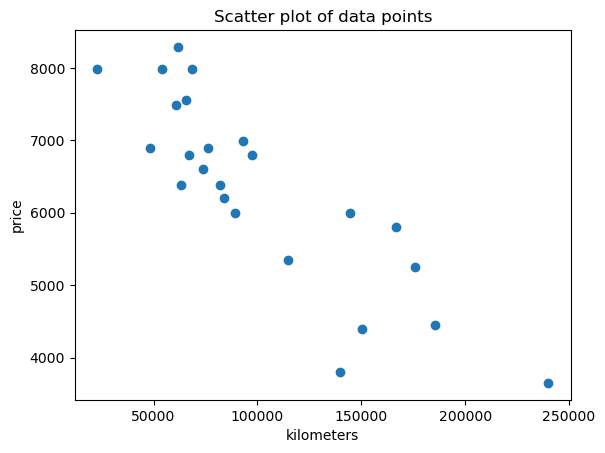

In [3]:
plt.plot(data['km'], data['price'], 'o')
plt.xlabel('kilometers')
plt.ylabel('price')
plt.title('Scatter plot of data points')
plt.show()

## Definition of cost function

Let's now define the `cost` function (`J`).

The purpose of the `cost function` is to determine the average cost(error) of the model chosen depending on the parameters we apply to that model.

Being a `linear_regression`, the model is represented as a linear function (a straight line on the cartesian plane) $f(x) = wx + b$, being `w` and `b` the parameters that respectively specify the `slope` and the vertical `offset` of the resulting line.

The cost function is calculated as the halved mean of the squared error of all the dataset entries given the two input parameters `w` and `b`:

$J(w, b) = \frac{1}{2m} \sum_{i=1}^{m} (f_{w, b}(x^i) - y^i)^2$

where $f(x^i) = w x^i + b$

Our final goal will be to **minimize the cost function** by training our model, so to have the best linear approximation available to predict the result.

Let's now code a vectorized `cost function` using `numPy` .

In [4]:
def cost_function(data, w, b, x_col='km', y_col='price'):
    """
    Standard 1/(2m) MSE cost: J = (1/(2m)) * sum( (w*x + b - y)^2 )
    Vectorized, numerically stable.
    """
    x = data[x_col].to_numpy(dtype=float)
    y = data[y_col].to_numpy(dtype=float)
    m = x.shape[0]
    y_hat = w * x + b
    err = y_hat - y
    return 0.5 * np.mean(err * err)


## Plotting linear regression function based on custom values

Let's now try some values and plot the resulting functions over the previous plot to grab a visual idea of how the different parameters chosen can get near to the optimal solution of minimizing the cost.

We'll start by choosing the values `0` for both `m` and `b`, and we'll then try some other values to grab the intuition.

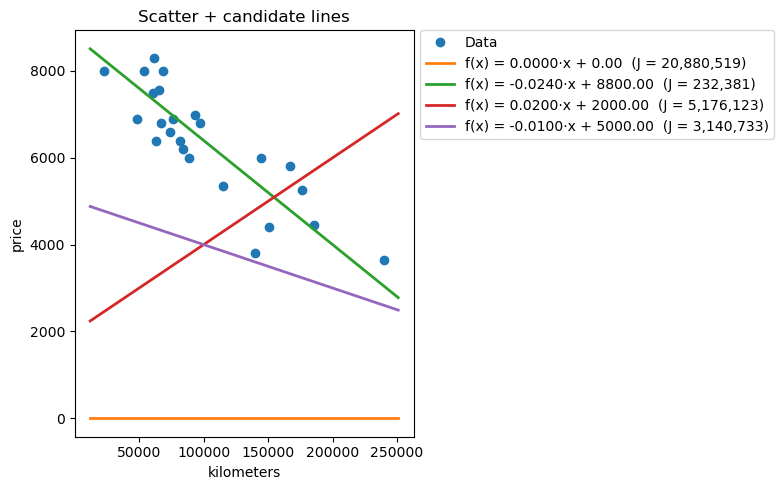

In [5]:
# Use existing cost_function(data, w, b)
# and 'data' DataFrame with 'km' and 'price' columns.

# 1) Make sure we have an ordered list of (w, b)
values_to_try = [
    (0.0, 0.0),
    (-0.0240, 8800.0),
    (0.02, 2000),
    (-0.01, 5000),
]

# 2) X range spanning the data, padded
x_min, x_max = data['km'].min(), data['km'].max()
pad = 0.05 * (x_max - x_min) if x_max > x_min else 1.0
x_plot = np.linspace(x_min - pad, x_max + pad, 200)

# 4) Plot
fig, ax = plt.subplots(figsize=(8, 5))

# Scatter of the dataset
ax.plot(data['km'], data['price'], 'o', label='Data')
ax.set_xlabel('kilometers')
ax.set_ylabel('price')
ax.set_title('Scatter + candidate lines')

# 5) Plot each candidate line
for i, (w, b) in enumerate(values_to_try):
    y_plot = w * x_plot + b
    # Compute cost
    J = cost_function(data, w, b)


    line, = ax.plot(x_plot, y_plot,
                    label=f"f(x) = {w:.4f}·x + {b:.2f}  (J = {J:,.0f})",
                    linewidth=2)

# Show legend
leg = ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0.)
fig.tight_layout()

plt.show()


## Defining a gradient descent

We can see from the previous plot how slightly modifications of paramaters can lead to very different cost functions.

Our goal is to find an algorithm that help us finding the optimal values for `w` and `b`. This means to define a `gradient descent` that suits our goal.

Gradient descent algorithm is an algorithm that takes into account parameters `w` and `b` and introduces a `learning rate` parameters to repeatedly calculate new values of `w` and `b` until they converge to a minimum:
1. $w = w - \alpha \frac{\delta}{\delta w} J_{(w,b)}$
2. $b = b - \alpha \frac{\delta}{\delta b} J_{(w,b)}$

where:
- $\alpha$ is  the `learning rate`
- $\frac{\delta}{\delta w} J_{(w,b)}$ is the (partial) derivative with respect to $w$ of the `cost function`
- $\frac{\delta}{\delta b} J_{(w,b)}$ is the (partial) derivative with respect to $b$ of the `cost function`

Given the previous definition of the `cost function` we can rewrite the previous calculations as:
1. $w = w - \alpha \frac{1}{m} \sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})x^{(i)}$
2. $b = b - \alpha \frac{1}{m} \sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})$

We will repeat steps #1 and #2 (**simultaneously**, not sequentially) with a defined `learning rate` constant value until the variation of `w` and `b` is lower than a defined treshold in its way to `cost function` = 0.

So let's define a function that computes the `gradient descent` for the linear regression of the given model, returning the `w` and `b` parameters that minimize the cost function for the model we are analyzing. It will use computed gradients (the partial derivatives) from the helper function `compute_gradients`.

Given that the range of `km` and `price` are very distant one from another, we will internally *normalize* the `km` feature using the **standard score**:

$x_{norm} = \frac{x - \mu}{\sigma}$

where:

- $x$ = original `km` value
- $\mu$ = mean of `km`
- $\sigma$ = standard deviation of `km`

We will also define some plotting functions to analyze how the `gradient descent` algorithm performs with different learning rate values.

In [15]:
def compute_gradients(data, w, b, x_col='km', y_col='price'):
    """
    dJ/dw = (1/m) * sum( (w*x + b - y) * x )
    dJ/db = (1/m) * sum( (w*x + b - y) )
    """
    x = data[x_col].to_numpy(dtype=float)
    y = data[y_col].to_numpy(dtype=float)
    m = x.shape[0]
    err = (w * x + b) - y
    dj_dw = (1.0 / m) * np.dot(err, x)
    dj_db = (1.0 / m) * np.sum(err)
    return dj_dw, dj_db

def gradient_descent(
    data,
    learning_rate,
    w0=0.0,
    b0=0.0,
    x_col='km',
    y_col='price',
    max_iters=100000,
    tol=1e-10,
    normalize=True,
    grad_clip=1e6,       # clip gradient norm to avoid explosions
    backoff=0.5,         # halve lr if cost gets worse/NaN
    patience=10,         # allow a few backoffs before giving up
    track_history=False
):
    """
    Gradient descent for y ≈ w*x + b.

    If normalize=True (default), we optimize on z = (x - mu)/sigma internally
    for stability and then return (w,b) in the *original* x units:

      w_real = w_norm / sigma
      b_real = b_norm - (w_norm * mu / sigma)

    Returns (w_final, b_final, history or None).
    """
    x = data[x_col].to_numpy(dtype=float)
    y = data[y_col].to_numpy(dtype=float)
    m = x.shape[0]

    # Internal scaling (only inside the optimizer)
    if normalize:
        mu = x.mean()
        sigma = x.std()
        if sigma == 0:
            sigma = 1.0
        z = (x - mu) / sigma
        # map (w_real, b_real) to normalized space initial (w,b)
        # initially w0,b0 are in real space; convert to normalized params:
        w = w0 * sigma          # inverse mapping of w_real = w_norm / sigma
        b = b0 + w0 * mu        # inverse mapping of b_real = b_norm - w_norm * mu / sigma  → b_norm = b_real + w_norm * mu / sigma
        # But since w_norm = w_real * sigma, b_norm = b_real + (w_real*sigma) * mu / sigma = b_real + w_real * mu
        x_used = z
    else:
        mu = 0.0
        sigma = 1.0
        z = x  # not used
        w = float(w0)
        b = float(b0)
        x_used = x

    def cost_on_used(wc, bc):
        err = (wc * x_used + bc) - y
        return 0.5 * np.mean(err * err)

    def grads_on_used(wc, bc):
        err = (wc * x_used + bc) - y
        dj_dw = (1.0 / m) * np.dot(err, x_used)
        dj_db = (1.0 / m) * np.sum(err)
        return dj_dw, dj_db

    J_prev = np.inf
    lr = float(learning_rate)
    backoffs_left = patience

    J_hist = []
    wb_hist = []

    for it in range(max_iters):
        dj_dw, dj_db = grads_on_used(w, b)

        # Gradient clipping (by L2 norm)
        gnorm = np.hypot(dj_dw, dj_db)
        if np.isfinite(gnorm) and gnorm > grad_clip:
            scale = grad_clip / gnorm
            dj_dw *= scale
            dj_db *= scale

        w_next = w - lr * dj_dw
        b_next = b - lr * dj_db

        J_next = cost_on_used(w_next, b_next)

        # If cost is NaN/Inf or increased significantly, back off LR and retry this step
        if not np.isfinite(J_next) or J_next > J_prev * 1.1:
            if backoffs_left <= 0:
                # give up and return what we have transformed back
                break
            lr *= backoff
            backoffs_left -= 1
            continue

        # Accept step
        if track_history:
            J_hist.append(J_next)
            wb_hist.append((w_next, b_next))

        # Convergence on cost improvement
        if abs(J_prev - J_next) < tol:
            w, b = w_next, b_next
            J_prev = J_next
            break

        w, b = w_next, b_next
        J_prev = J_next

    # Map back to *original* x units if we normalized internally
    if normalize:
        # w_real = w_norm / sigma
        # b_real = b_norm - (w_norm * mu / sigma)
        w_real = w / sigma
        b_real = b - (w * mu / sigma)
    else:
        w_real, b_real = w, b

    history = None
    if track_history:
        history = {'J': J_hist, 'params_used_space': wb_hist}

    return w_real, b_real, history

def plot_multiple_cost_histories(histories, labels=None, title="Cost function over iterations"):
    """
    Plot multiple cost histories on a single figure for comparison.
    
    Parameters:
        histories : list of history dicts (from gradient_descent)
        labels    : list of str, same length as histories (optional)
        title     : str, chart title
    """
    if labels is None:
        labels = [f"Run {i+1}" for i in range(len(histories))]

    fig, ax = plt.subplots(figsize=(9, 5))

    for hist, label in zip(histories, labels):
        if hist is None or 'J' not in hist or len(hist['J']) == 0:
            print(f"⚠️ Skipping {label}: no cost history.")
            continue

        J_vals = np.array(hist['J'])
        iters = np.arange(1, len(J_vals)+1)
        ax.plot(iters, J_vals, lw=2, label=label)

    ax.set_xlabel('Iteration')
    ax.set_ylabel('Cost J(w,b)')
    ax.set_title(title)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='best')
    plt.tight_layout()
    plt.show()


## Plotting results

Let's try now to plot how cost converge at different learning rates.
We will use the following `learning_rate` values:
- 1e-6 (0.000001)
- 1e-5 (0.00001)
- 1e-4 (0.0001)
- 1e-3 (0.001)
- 1e-2 (0.01)
- 5e-2 (0.05)

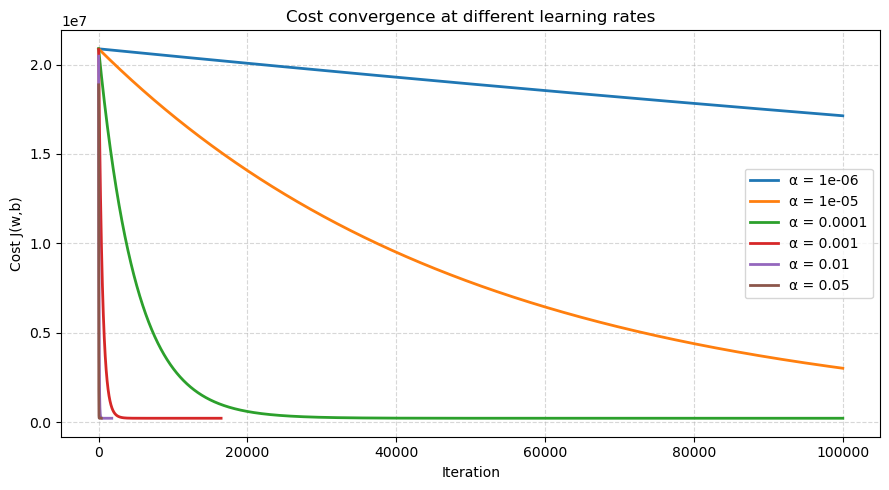

In [16]:
# Try multiple learning rates
histories = []
labels = []
learning_rates = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 5e-2]

for alpha in learning_rates:
    w_, b_, hist_ = gradient_descent(
        data,
        learning_rate=alpha,
        normalize=True,
        track_history=True
    )
    histories.append(hist_)
    labels.append(f"α = {alpha}")

plot_multiple_cost_histories(histories, labels, title="Cost convergence at different learning rates")


# Plot analysis

As we can see, the learning rates `0.05` and `0.01` minimize the cost function pretty fast and well before the default 1,000,000 `max_iterations` defined.

Let's see a textual representation of previous learning rates also:

In [17]:
scenarios = []

for lr in learning_rates:
    w_star, b_star, hist = gradient_descent(
        data,
        learning_rate=lr,   # stable & fast when normalized
        w0=0.0,
        b0=0.0,
        x_col='km',
        y_col='price',
        normalize=True,       # <- internal scaling; returns (w,b) in original units
        max_iters=100000,
        tol=1e-12,
        track_history=True
    )
    scenarios.append((lr, w_star, b_star, hist['J']))
    
for idx, scenario in enumerate(scenarios):
    print(f"### Scenario {idx + 1}: learning rate = {scenario[0]} ###")
    print(f"w*: {scenario[1]:.6f}, b*: {scenario[2]:.6f}")
    print(f"final cost: {scenario[3][-1]:.6f}, iterations tracked: {len(scenario[3])}\n")


### Scenario 1: learning rate = 1e-06 ###
w*: -0.002041, b*: 808.844233
final cost: 17135912.482000, iterations tracked: 100000

### Scenario 2: learning rate = 1e-05 ###
w*: -0.013558, b*: 5372.787315
final cost: 3018509.895069, iterations tracked: 100000

### Scenario 3: learning rate = 0.0001 ###
w*: -0.021448, b*: 8499.213962
final cost: 222822.665072, iterations tracked: 100000

### Scenario 4: learning rate = 0.001 ###
w*: -0.021449, b*: 8499.599115
final cost: 222822.622536, iterations tracked: 16573

### Scenario 5: learning rate = 0.01 ###
w*: -0.021449, b*: 8499.599498
final cost: 222822.622536, iterations tracked: 1775

### Scenario 6: learning rate = 0.05 ###
w*: -0.021449, b*: 8499.599601
final cost: 222822.622536, iterations tracked: 370



## Conclusions

We can see that scenarios `4`, `5` and `6` yield the same final cost (which is also the best cost achieved among all scenarios).
The scenario `6` (having a learning_rate = `0.05`) gets it in just 370 iterations.

We can safely consider a learning rate of `0.05` (for the normalized `km` feature) a very valid acceptable candidate.

So let's finally plot our `linear regression` function with the parameters determined by our chosen learning rate alongside the scattered plot of the dataset, to have a final visual representation of the situation.

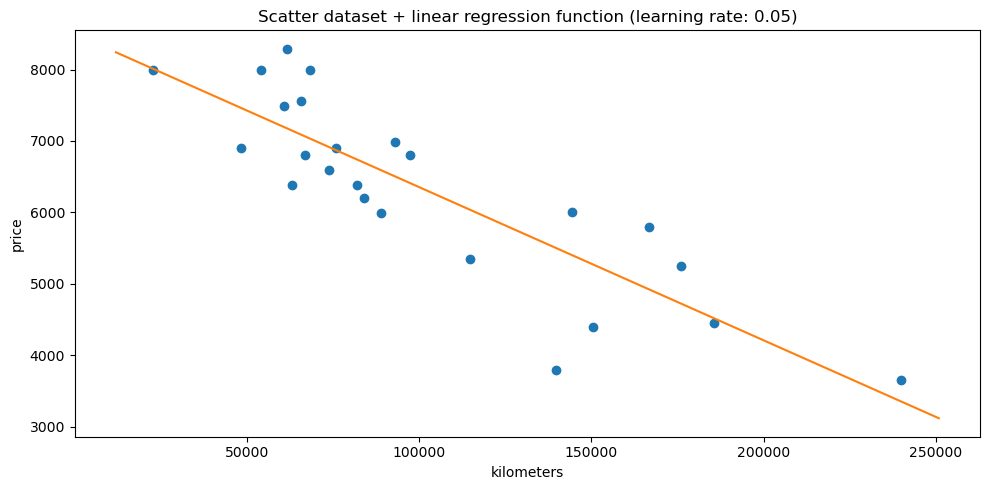

In [18]:
x_min, x_max = data['km'].min(), data['km'].max()
pad = 0.05 * (x_max - x_min) if x_max > x_min else 1.0
x_plot = np.linspace(x_min - pad, x_max + pad, 200)
fig, ax = plt.subplots(figsize=(10, 5))

# Scatter of the dataset
ax.plot(data['km'], data['price'], 'o', label='Data')
ax.set_xlabel('kilometers')
ax.set_ylabel('price')
ax.set_title('Scatter dataset + linear regression function (learning rate: 0.05)')

w, b = gradient_descent(data, 0.05)[0:2]
# Plot of linear regression model using 0.05 as learning rate
y_plot = w * x_plot + b

line, = ax.plot(x_plot, y_plot)
fig.tight_layout()

plt.show()
